<a href="https://colab.research.google.com/github/Beebah-rahman09/inorganic-materials-band-gap-prediction/blob/main/Project_01_Machine_Learning_Materials_Discovery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# PROJECT 01
# Machine Learning-Based Prediction of Electronic Band Gaps
# Researcher: Habiba Abdulrahman Abdullahi

import sys
import platform

project_title = (
    "Machine Learning-Based Prediction of Electronic "
    "Band Gaps in Inorganic Materials"
)

research_question = (
    "Can machine learning models predict the electronic "
    "band gaps of inorganic materials?"
)

research_objectives = [
    "Understand the scientific meaning of electronic band gaps.",
    "Explore an established materials science dataset.",
    "Prepare and analyse scientific data.",
    "Train and evaluate machine learning models.",
    "Interpret the results and their scientific limitations."
]

print("RESEARCH PROJECT 01")
print("=" * 45)
print("Title:", project_title)
print("\nResearch question:", research_question)

print("\nResearch objectives:")
for number, objective in enumerate(research_objectives, 1):
    print(f"{number}. {objective}")

print("\nPython version:", sys.version)
print("Platform:", platform.platform())

print("\nResearch environment successfully started!")


RESEARCH PROJECT 01
Title: Machine Learning-Based Prediction of Electronic Band Gaps in Inorganic Materials

Research question: Can machine learning models predict the electronic band gaps of inorganic materials?

Research objectives:
1. Understand the scientific meaning of electronic band gaps.
2. Explore an established materials science dataset.
3. Prepare and analyse scientific data.
4. Train and evaluate machine learning models.
5. Interpret the results and their scientific limitations.

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

Research environment successfully started!


In [ ]:

%pip -q install matbench

print("MatBench installation step completed.")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> scikit-learn

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
MatBench installation step completed.


In [ ]:
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nOur research environment is ready!")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1

Our research environment is ready!


In [ ]:
research_notes = {
    "property": "Electronic band gap",
    "measurement": "Electronvolts (eV)",
    "dataset": "MatBench matbench_mp_gap",
    "number_of_entries": 106113,
    "research_method": "Supervised machine learning",
    "main_goal": "Predict electronic band gaps"
}

print("PROJECT 01: SCIENTIFIC BACKGROUND")
print("=" * 45)

for key, value in research_notes.items():
    print(f"{key.replace('_', ' ').title()}: {value}")

PROJECT 01: SCIENTIFIC BACKGROUND
Property: Electronic band gap
Measurement: Electronvolts (eV)
Dataset: MatBench matbench_mp_gap
Number Of Entries: 106113
Research Method: Supervised machine learning
Main Goal: Predict electronic band gaps


In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/materialsproject/matbench/main/matbench/data/megnet_structure/mp_gap.csv"

try:
    data = pd.read_csv(url)
    print("Dataset downloaded successfully!")
    print("Dataset shape:", data.shape)
    display(data.head())
except Exception as e:
    print("Download attempt failed:", e)

Download attempt failed: HTTP Error 404: Not Found


In [ ]:
import requests
import gzip
import json

url = "https://ml.materialsproject.org/projects/matbench_mp_gap.json.gz"

response = requests.get(url, timeout=120)
response.raise_for_status()

dataset_bytes = gzip.decompress(response.content)
dataset = json.loads(dataset_bytes.decode("utf-8"))

print("Dataset downloaded successfully!")
print("Data type:", type(dataset))

if isinstance(dataset, dict):
    print("Available fields:", list(dataset.keys()))
elif isinstance(dataset, list):
    print("Number of records:", len(dataset))
    print("First record:", dataset[0])

Dataset downloaded successfully!
Data type: <class 'dict'>
Available fields: ['index', 'columns', 'data']


In [ ]:
import pandas as pd

df = pd.DataFrame(
    dataset["data"],
    columns=dataset["columns"],
    index=dataset["index"]
)

print("Dataset successfully converted!")
print("\nDataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

Dataset successfully converted!

Dataset dimensions: (106113, 2)

Column names:
['structure', 'gap pbe']

First five records:


,structure,gap pbe
0,"{'@module': 'pymatgen.core.structure', '@class...",1.3322
1,"{'@module': 'pymatgen.core.structure', '@class...",0.0000
2,"{'@module': 'pymatgen.core.structure', '@class...",0.0000
3,"{'@module': 'pymatgen.core.structure', '@class...",0.4113
4,"{'@module': 'pymatgen.core.structure', '@class...",0.3514


In [ ]:
import numpy as np

band_gaps = df["gap pbe"]

print("BAND GAP DATA ANALYSIS")
print("=" * 40)

print("Total materials:", len(band_gaps))
print("Missing values:", band_gaps.isna().sum())
print("Average band gap:", round(band_gaps.mean(), 4), "eV")
print("Median band gap:", round(band_gaps.median(), 4), "eV")
print("Minimum band gap:", round(band_gaps.min(), 4), "eV")
print("Maximum band gap:", round(band_gaps.max(), 4), "eV")
print("Standard deviation:", round(band_gaps.std(), 4), "eV")

print("\nNumber of zero-band-gap materials:",
      (band_gaps == 0).sum())

print("Number of positive-band-gap materials:",
      (band_gaps > 0).sum())

BAND GAP DATA ANALYSIS
Total materials: 106113
Missing values: 0
Average band gap: 1.2146 eV
Median band gap: 0.2738 eV
Minimum band gap: 0.0 eV
Maximum band gap: 9.7212 eV
Standard deviation: 1.599 eV

Number of zero-band-gap materials: 46151
Number of positive-band-gap materials: 59962


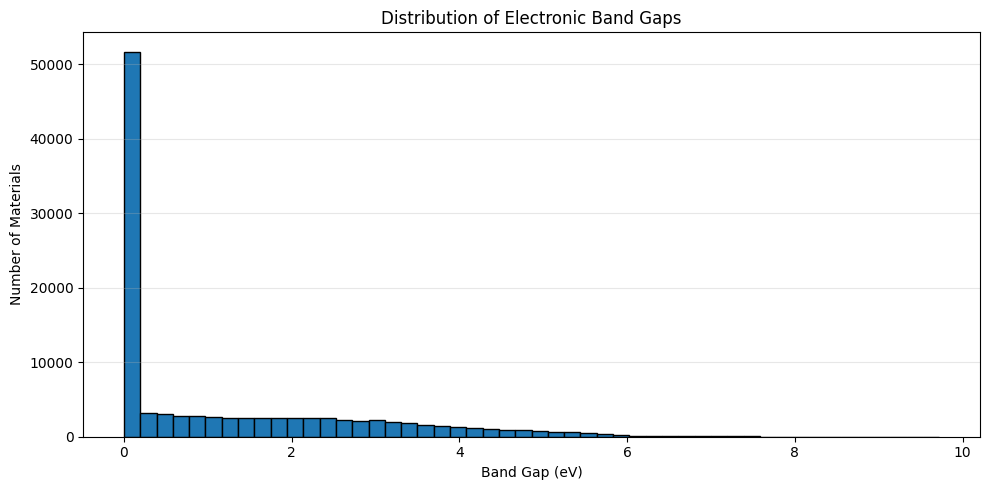

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["gap pbe"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Electronic Band Gaps")
plt.xlabel("Band Gap (eV)")
plt.ylabel("Number of Materials")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
graph_interpretation = """
The histogram of electronic band gaps shows a
positively skewed distribution. Most materials
have relatively small band-gap values, while
fewer materials have larger band gaps.

The mean (1.2146 eV) is greater than the
median (0.2738 eV), supporting this observation.
"""

print("SCIENTIFIC INTERPRETATION")
print(graph_interpretation)

SCIENTIFIC INTERPRETATION

The histogram of electronic band gaps shows a
positively skewed distribution. Most materials
have relatively small band-gap values, while
fewer materials have larger band gaps.

The mean (1.2146 eV) is greater than the
median (0.2738 eV), supporting this observation.



In [ ]:
# Select materials with positive band gaps

positive_materials = df[df["gap pbe"] > 0].copy()

print("DATASET PREPARATION")
print("=" * 40)

print("Original dataset:", len(df))
print("Positive-gap materials:", len(positive_materials))
print("Excluded zero-gap materials:",
      len(df) - len(positive_materials))

print("\nMinimum positive band gap:",
      positive_materials["gap pbe"].min())

print("Maximum positive band gap:",
      positive_materials["gap pbe"].max())

print("\nPrepared dataset is ready!")

DATASET PREPARATION
Original dataset: 106113
Positive-gap materials: 59962
Excluded zero-gap materials: 46151

Minimum positive band gap: 9.999999999976694e-05
Maximum positive band gap: 9.721200000000001

Prepared dataset is ready!


In [ ]:
%pip -q install pymatgen

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
import pymatgen
import requests

print("Pymatgen version:", pymatgen.__version__)
print("Requests version:", requests.__version__)
print("Materials science library is ready!")

AttributeError: module 'pymatgen' has no attribute '__version__'

In [ ]:
from pymatgen.core import Structure
from importlib.metadata import version

print("Pymatgen version:", version("pymatgen"))

example_structure = Structure.from_dict(
    positive_materials.iloc[0]["structure"]
)

print("\nMATERIAL STRUCTURE TEST")
print("=" * 35)

print("Chemical formula:",
      example_structure.composition.reduced_formula)

print("Number of atoms:", len(example_structure))

print("Number of elements:",
      len(example_structure.composition.elements))

print("Elements:",
      [str(e) for e in example_structure.composition.elements])

print("\nPymatgen is working successfully!")

Pymatgen version: 2026.10.24

MATERIAL STRUCTURE TEST
Chemical formula: KMnO2
Number of atoms: 16
Number of elements: 3
Elements: ['K', 'Mn', 'O']

Pymatgen is working successfully!


In [ ]:
import numpy as np
import pandas as pd
from pymatgen.core import Structure

sample = positive_materials.sample(
    n=1000,
    random_state=42
)

features = []

for index, row in sample.iterrows():

    structure = Structure.from_dict(row["structure"])
    elements = structure.composition.elements

    atomic_numbers = np.array([el.Z for el in elements])
    amounts = np.array([
        structure.composition[el] for el in elements
    ])

    atomic_masses = np.array([
        float(el.atomic_mass) for el in elements
    ])

    atomic_fractions = amounts / amounts.sum()

    features.append({
        "number_of_atoms": len(structure),
        "number_of_elements": len(elements),
        "mean_atomic_number": np.average(
            atomic_numbers, weights=atomic_fractions
        ),
        "min_atomic_number": atomic_numbers.min(),
        "max_atomic_number": atomic_numbers.max(),
        "mean_atomic_mass": np.average(
            atomic_masses, weights=atomic_fractions
        ),
        "atomic_number_variation": np.average(
            (atomic_numbers - np.average(
                atomic_numbers, weights=atomic_fractions
            )) ** 2,
            weights=atomic_fractions
        ) ** 0.5
    })

X = pd.DataFrame(features)
y = sample["gap pbe"].reset_index(drop=True)

print("FEATURE EXTRACTION COMPLETE")
print("=" * 40)
print("Materials processed:", len(X))
print("Number of features:", X.shape[1])

display(X.head())

FEATURE EXTRACTION COMPLETE
Materials processed: 1000
Number of features: 7


,number_of_atoms,number_of_elements,mean_atomic_number,min_atomic_number,max_atomic_number,mean_atomic_mass,atomic_number_variation
0,26,5,10.307692,6,24,21.226590,4.529979
1,68,3,34.235294,16,75,78.964941,20.746451
2,4,3,60.500000,52,80,148.500226,11.324752
3,10,4,21.800000,11,65,48.116889,15.131424
4,44,5,7.545455,1,49,15.538436,10.039591


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Create the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

# Make predictions
predictions = model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("RANDOM FOREST MODEL RESULTS")
print("=" * 40)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Mean Absolute Error:", round(mae, 4), "eV")
print("Root Mean Squared Error:", round(rmse, 4), "eV")
print("R-squared:", round(r2, 4))

RANDOM FOREST MODEL RESULTS
Training samples: 800
Testing samples: 200
Mean Absolute Error: 1.015 eV
Root Mean Squared Error: 1.3675 eV
R-squared: 0.1444


In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Create a simple baseline model
baseline = DummyRegressor(strategy="mean")

# Train the baseline
baseline.fit(X_train, y_train)

# Make predictions
baseline_predictions = baseline.predict(X_test)

# Calculate baseline performance
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

print("MODEL COMPARISON")
print("=" * 45)

print("                    BASELINE    RANDOM FOREST")
print(f"MAE:                {baseline_mae:.4f}      {mae:.4f}")
print(f"RMSE:               {baseline_rmse:.4f}      {rmse:.4f}")
print(f"R-squared:          {baseline_r2:.4f}      {r2:.4f}")

MODEL COMPARISON
                    BASELINE    RANDOM FOREST
MAE:                1.2162      1.0150
RMSE:               1.4818      1.3675
R-squared:          -0.0045      0.1444


FEATURE IMPORTANCE ANALYSIS


,Feature,Importance
4,max_atomic_number,0.258416
6,atomic_number_variation,0.186736
5,mean_atomic_mass,0.146424
2,mean_atomic_number,0.142318
0,number_of_atoms,0.124599
3,min_atomic_number,0.105420
1,number_of_elements,0.036087


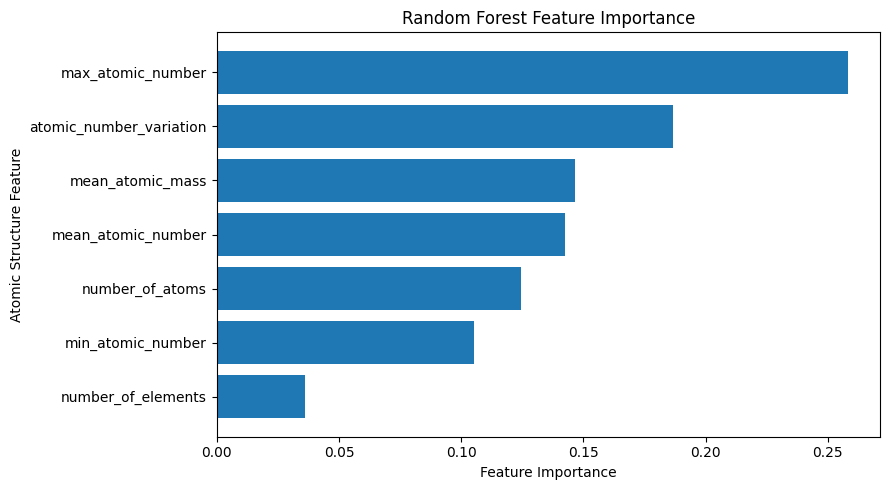

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 40)

display(importance)

plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Atomic Structure Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

FEATURE IMPORTANCE ANALYSIS


,Feature,Importance
4,max_atomic_number,0.258416
6,atomic_number_variation,0.186736
5,mean_atomic_mass,0.146424
2,mean_atomic_number,0.142318
0,number_of_atoms,0.124599
3,min_atomic_number,0.105420
1,number_of_elements,0.036087


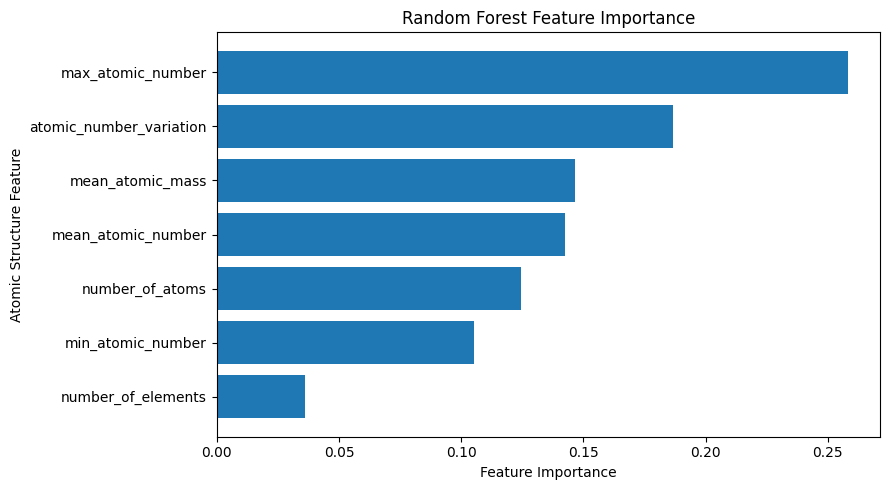

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 40)

display(importance)

plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Atomic Structure Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

FEATURE IMPORTANCE ANALYSIS


,Feature,Importance
4,max_atomic_number,0.258416
6,atomic_number_variation,0.186736
5,mean_atomic_mass,0.146424
2,mean_atomic_number,0.142318
0,number_of_atoms,0.124599
3,min_atomic_number,0.105420
1,number_of_elements,0.036087


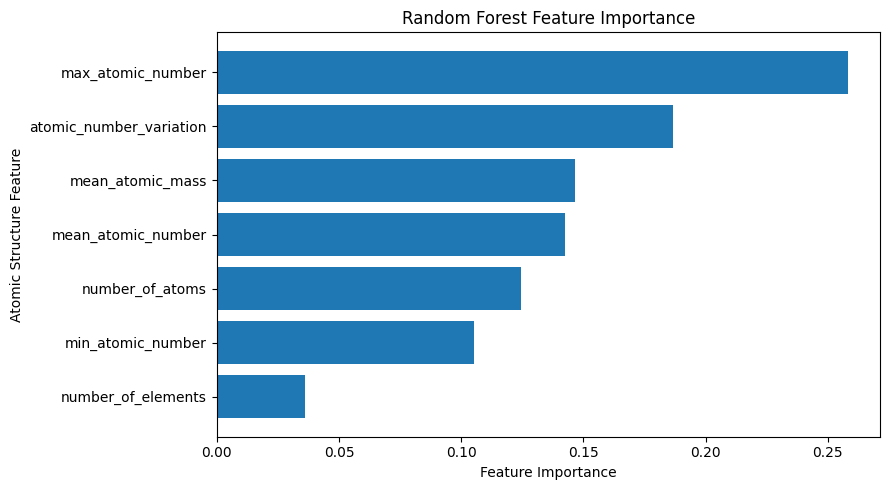

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 40)

display(importance)

plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Atomic Structure Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Create a new model
extra_model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
extra_model.fit(X_train, y_train)

# Make predictions
extra_predictions = extra_model.predict(X_test)

# Evaluate the model
extra_mae = mean_absolute_error(
    y_test, extra_predictions
)

extra_rmse = np.sqrt(
    mean_squared_error(y_test, extra_predictions)
)

extra_r2 = r2_score(y_test, extra_predictions)

print("MODEL IMPROVEMENT EXPERIMENT")
print("=" * 45)

print("Random Forest MAE:", round(mae, 4))
print("Extra Trees MAE:", round(extra_mae, 4))

print("\nRandom Forest RMSE:", round(rmse, 4))
print("Extra Trees RMSE:", round(extra_rmse, 4))

print("\nRandom Forest R2:", round(r2, 4))
print("Extra Trees R2:", round(extra_r2, 4))

MODEL IMPROVEMENT EXPERIMENT
Random Forest MAE: 1.015
Extra Trees MAE: 1.0375

Random Forest RMSE: 1.3675
Extra Trees RMSE: 1.3944

Random Forest R2: 0.1444
Extra Trees R2: 0.1105


In [ ]:
# Select 5,000 positive-gap materials
larger_sample = positive_materials.sample(
    n=5000,
    random_state=42
)

features_large = []

for index, row in larger_sample.iterrows():

    structure = Structure.from_dict(row["structure"])
    elements = structure.composition.elements

    atomic_numbers = np.array([el.Z for el in elements])
    amounts = np.array([
        structure.composition[el] for el in elements
    ])

    atomic_masses = np.array([
        float(el.atomic_mass) for el in elements
    ])

    fractions = amounts / amounts.sum()

    features_large.append({
        "number_of_atoms": len(structure),
        "number_of_elements": len(elements),
        "mean_atomic_number": np.average(
            atomic_numbers, weights=fractions
        ),
        "min_atomic_number": atomic_numbers.min(),
        "max_atomic_number": atomic_numbers.max(),
        "mean_atomic_mass": np.average(
            atomic_masses, weights=fractions
        ),
        "atomic_number_variation": np.average(
            (atomic_numbers - np.average(
                atomic_numbers, weights=fractions
            )
        ) ** 2, weights=fractions) ** 0.5
    })

X_large = pd.DataFrame(features_large)
y_large = larger_sample["gap pbe"].reset_index(drop=True)

print("Larger dataset prepared!")
print("Materials:", len(X_large))
print("Features:", X_large.shape[1])

Larger dataset prepared!
Materials: 5000
Features: 7


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Split the larger dataset
X_train_large, X_test_large, y_train_large, y_test_large = train_test_split(
    X_large,
    y_large,
    test_size=0.20,
    random_state=42
)

# Create and train the model
large_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

large_model.fit(X_train_large, y_train_large)

# Make predictions
large_predictions = large_model.predict(X_test_large)

# Evaluate
large_mae = mean_absolute_error(y_test_large, large_predictions)

large_rmse = np.sqrt(
    mean_squared_error(y_test_large, large_predictions)
)

large_r2 = r2_score(y_test_large, large_predictions)

print("LARGER DATASET MODEL RESULTS")
print("=" * 45)

print("Training materials:", len(X_train_large))
print("Testing materials:", len(X_test_large))
print("MAE:", round(large_mae, 4), "eV")
print("RMSE:", round(large_rmse, 4), "eV")
print("R-squared:", round(large_r2, 4))

LARGER DATASET MODEL RESULTS
Training materials: 4000
Testing materials: 1000
MAE: 0.8972 eV
RMSE: 1.1905 eV
R-squared: 0.4425


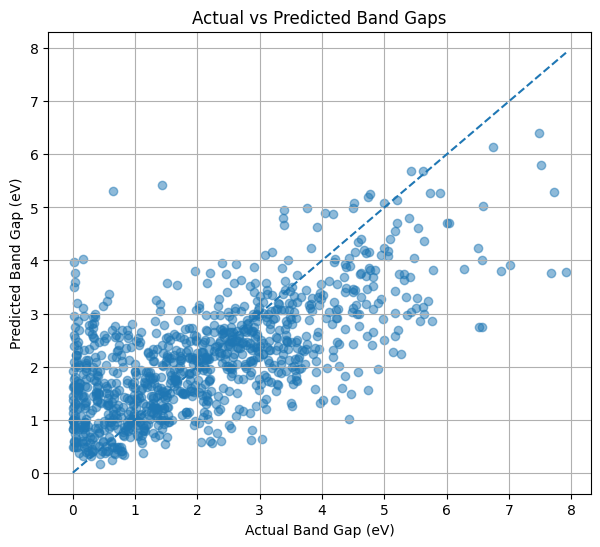

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test_large,
    large_predictions,
    alpha=0.5
)

plt.plot(
    [0, max(y_test_large)],
    [0, max(y_test_large)],
    linestyle="--"
)

plt.xlabel("Actual Band Gap (eV)")
plt.ylabel("Predicted Band Gap (eV)")
plt.title("Actual vs Predicted Band Gaps")
plt.grid(True)

plt.show()

In [ ]:
mae_improvement = (
    (1.0150 - 0.8972) / 1.0150
) * 100

rmse_improvement = (
    (1.3675 - 1.1905) / 1.3675
) * 100

print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

MAE improvement: 11.61%
RMSE improvement: 12.94%


In [ ]:
import joblib

joblib.dump(large_model, "band_gap_random_forest.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
results = X_large.copy()

results["actual_band_gap"] = y_large.values
results["predicted_band_gap"] = large_predictions

results.to_csv("band_gap_predictions.csv", index=False)

print("Prediction results saved successfully!")

ValueError: Length of values (1000) does not match length of index (5000)

In [ ]:
results = X_test_large.copy()

results["actual_band_gap"] = y_test_large.values
results["predicted_band_gap"] = large_predictions

results.to_csv("band_gap_predictions.csv", index=False)

print("Prediction results saved successfully!")
print("Number of predictions:", len(results))

Prediction results saved successfully!
Number of predictions: 1000


In [ ]:
from google.colab import files

files.download("band_gap_random_forest.pkl")
files.download("band_gap_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>